### feature scaling:
types of feature scaling
1. standardization
2. normalization

#z-score normalization/standardization
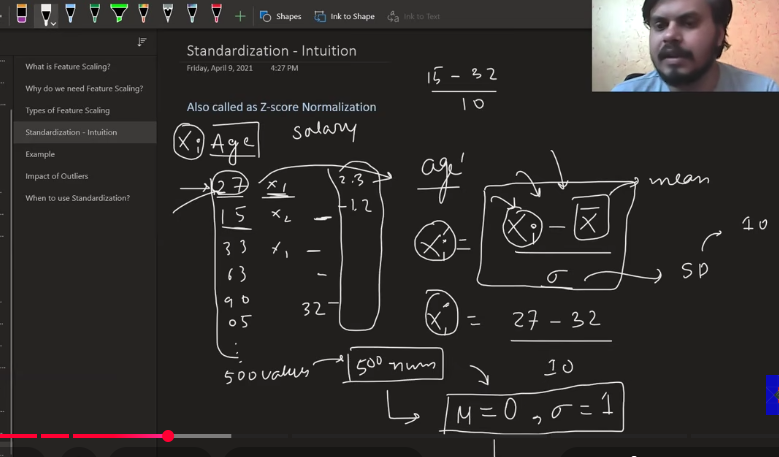

>Mean always 0 and standard deviation always 1
>In standarization we do 2 things either scale up or scale down if mean is greater than 1 than we scale down else scale up
---

**example code**


In [7]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv("/home/raghav/ML(100dayseries)/100-days-of-ml-campusx/feature_engineering/Social_Network_Ads.csv")

In [9]:
df = df.iloc[:,2:5] #only keeping the column we need to scale down

In [10]:
df.sample(5)

,Age,EstimatedSalary,Purchased
353,37,57000,0
335,36,54000,0
160,32,100000,1
175,23,28000,0
49,31,89000,0


## **Train Test Split**

In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test,Y_train, Y_test = train_test_split( df.drop('Purchased',axis=1),#removing purshased
                                                    df['Purchased'],
                                                    test_size=0.3,
                                                    random_state=0)

In [12]:
X_test.shape , X_train.shape

((120, 2), (280, 2))

## **StandardScalar**

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

#fit the data to learn the parameters like mean std
scaler.fit(X_train)

#transform both train and test
X_train_scaled=scaler.transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [14]:
scaler.var_

array([1.04038724e+02, 1.19572709e+09])

In [15]:
X_train_scaled=pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled=pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [16]:
np.round(X_train.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,37.9,69807.1
std,10.2,34641.2
min,18.0,15000.0
25%,30.0,43000.0
50%,37.0,70500.0
75%,46.0,88000.0
max,60.0,150000.0


In [17]:
np.round(X_train_scaled.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.2,2.3


In [18]:
np.round(X_test_scaled.describe(),1)

,Age,EstimatedSalary
count,120.0,120.0
mean,-0.1,-0.0
std,1.1,1.0
min,-1.9,-1.6
25%,-1.0,-0.7
50%,-0.2,-0.2
75%,0.7,0.5
max,2.2,2.3


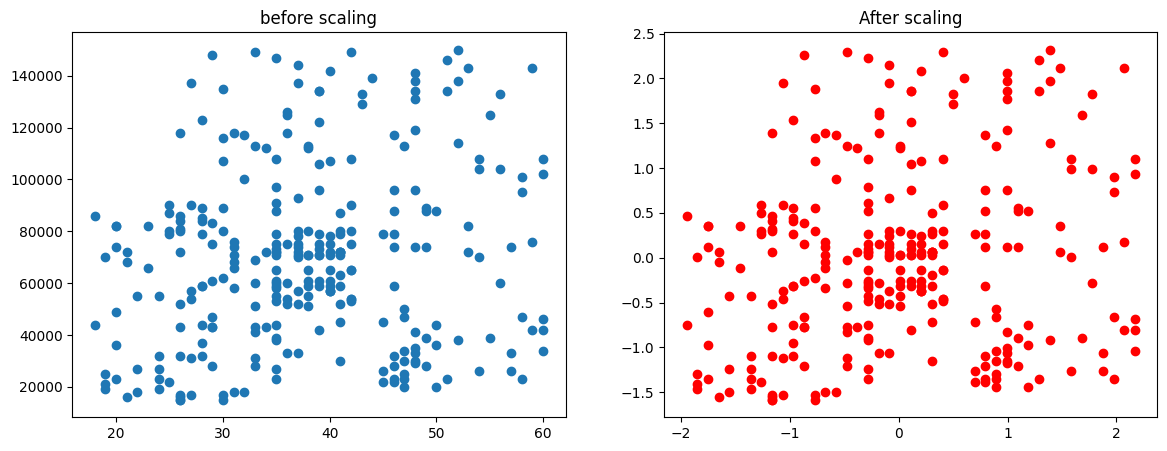

In [19]:
fig,(ax1, ax2)= plt.subplots(ncols=2,figsize=(14,5))

ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title("before scaling")

ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'],color='red')
ax2.set_title("After scaling")
plt.show()

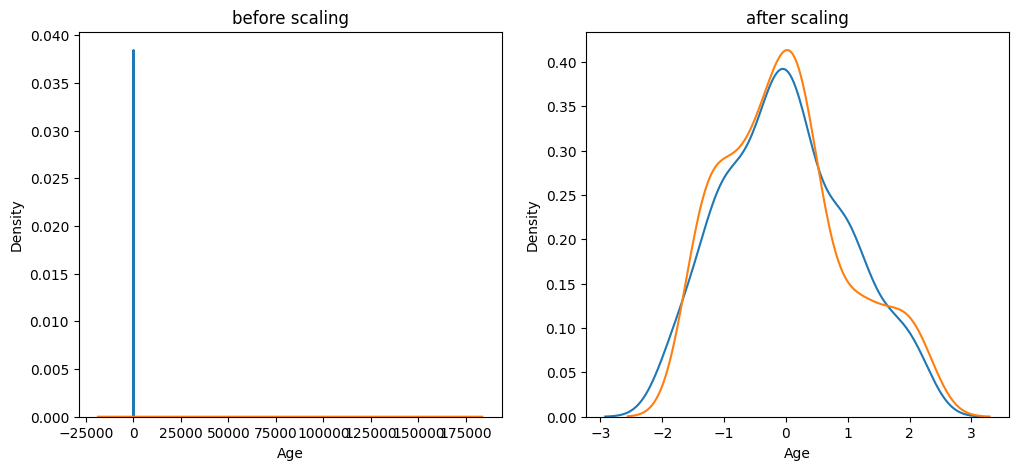

In [20]:
fig, (ax1,ax2) = plt.subplots(ncols=2,figsize=(12,5))

#before scaling
ax1.set_title("before scaling")
sns.kdeplot(X_train['Age'], ax=ax1)
sns.kdeplot(X_train['EstimatedSalary'],ax=ax1)

#after scaling
ax2.set_title("after scaling")
sns.kdeplot(X_train_scaled['Age'], ax=ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'],ax=ax2)
plt.show()



1. we cant compare curve without scaling as we can see above 
2. we use prob density curve to campare how prob density at in x axis
3. scaling doesnt affect the distribution curve


# *Why scaling is important*

In [35]:
from sklearn.linear_model import LogisticRegression

In [36]:
lr = LogisticRegression()
lr_scaled = LogisticRegression()

In [37]:
lr.fit(X_train,Y_train)
lr_scaled.fit(X_train_scaled, Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [38]:
y_pred = lr.predict(X_test)
y_pred_scaled=lr_scaled.predict(X_test_scaled)

In [39]:
from sklearn.metrics import accuracy_score

In [40]:
print("Original : ", accuracy_score(Y_test, y_pred))
print("Scaled : " , accuracy_score(Y_test, y_pred_scaled))

Original :  0.875
Scaled :  0.8666666666666667


# decision tree doesnt have any effeect with scaling
# Decision Tree Classifier

## 1. What is a Decision Tree?

A Decision Tree is a **supervised machine learning algorithm** used for classification and regression.

It makes predictions by asking a sequence of questions about the input features and following the answers until it reaches a final prediction.

It works similarly to making decisions in real life.

**Example: Should I play cricket?**

- Is it raining?
  - Yes → Don't play.
  - No → Play.

A Decision Tree follows the same approach to make predictions from data.

### Important Terminology

- **Root Node:** The starting point of the tree, containing the entire dataset.
- **Decision Node:** A node where a condition or question is applied.
- **Branch:** The outcome of a decision.
- **Leaf Node:** The final node containing the prediction.

---

## 2. How Does a Decision Tree Work?

Let's consider a Social Network Ads dataset.

| Age | Salary | Purchased |
|---|---:|---|
| 22 | 20,000 | No |
| 25 | 40,000 | No |
| 35 | 80,000 | Yes |
| 45 | 90,000 | Yes |
| 50 | 120,000 | Yes |

The Decision Tree tries to find the best feature and threshold to divide the dataset.

For example:

**Question: Is Age <= 30?**

- Yes → Mostly No purchases.
- No → Mostly Yes purchases.

This is a good split because it separates the two classes.


### Steps followed by a Decision Tree

1. Start with the entire training dataset (Root Node).
2. Try different features and thresholds to split the data.
3. Calculate the impurity of the resulting groups.
4. Choose the split that produces the best separation.
5. Repeat the process recursively on the child nodes.
6. Stop when a stopping condition is reached.
7. Assign a prediction to each leaf node.

But how does the Decision Tree decide which split is best?

It uses **Gini Impurity or Entropy**.
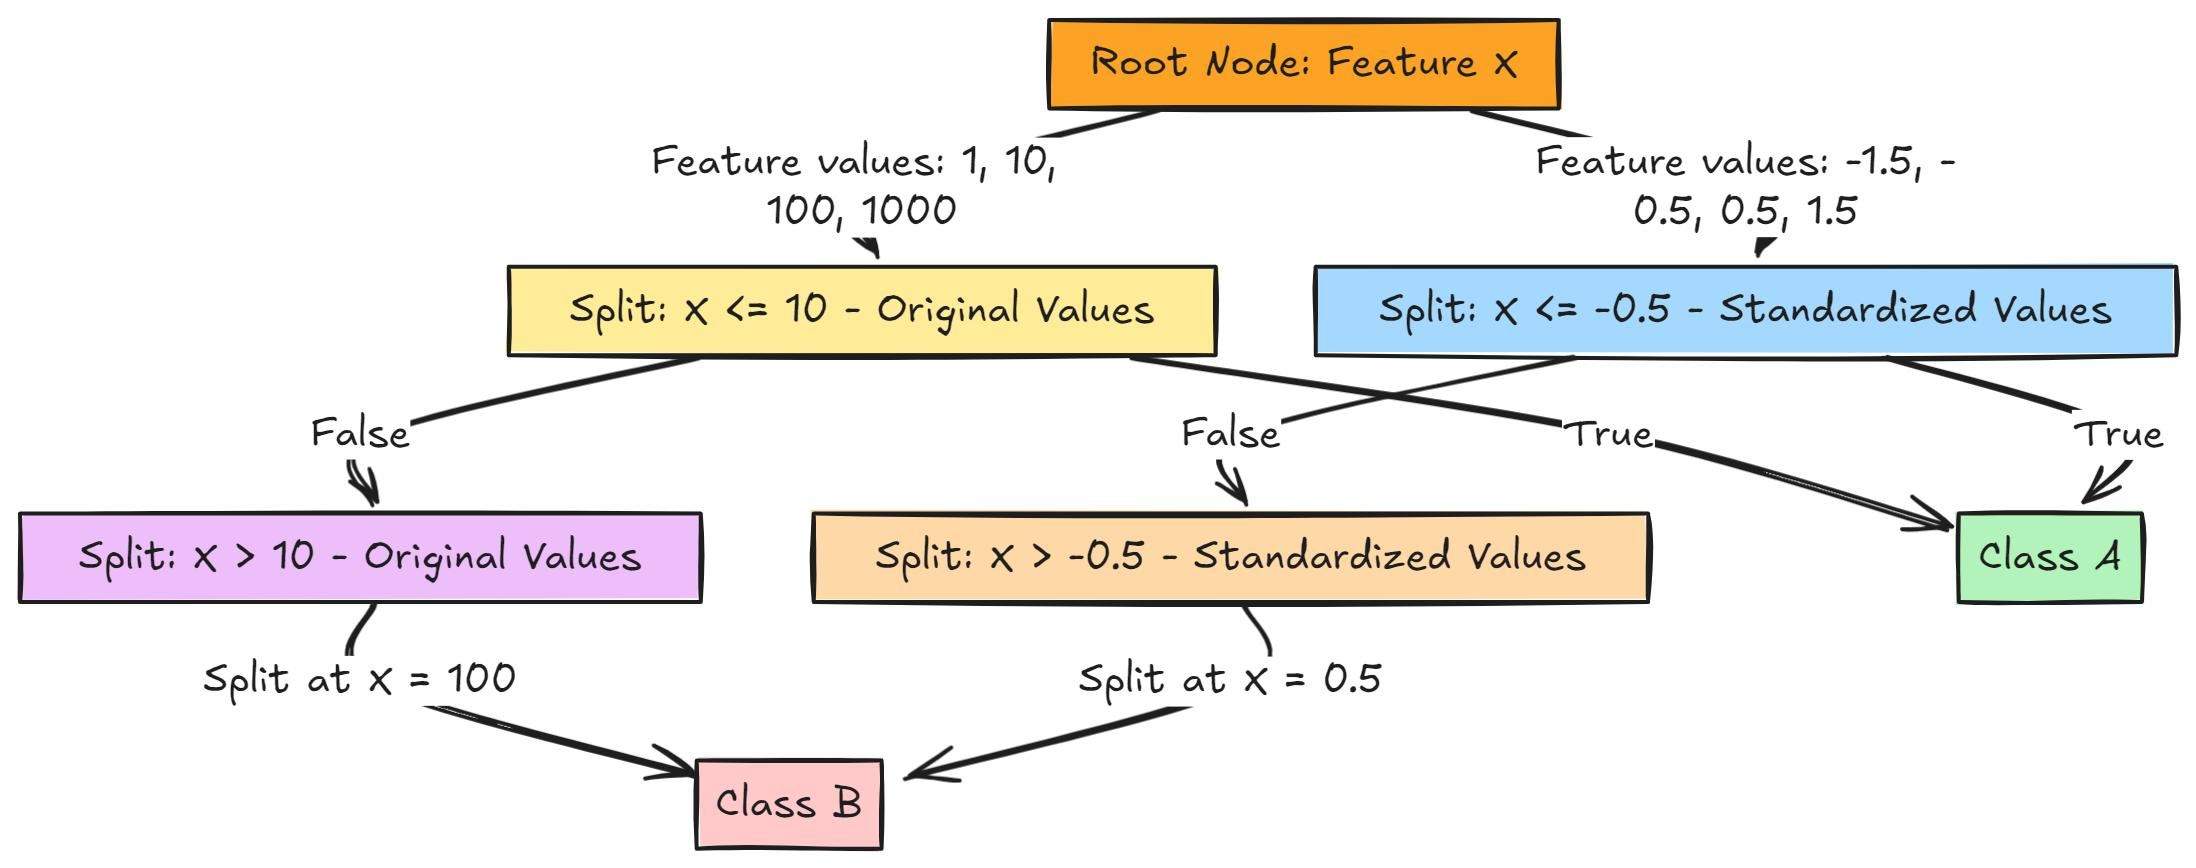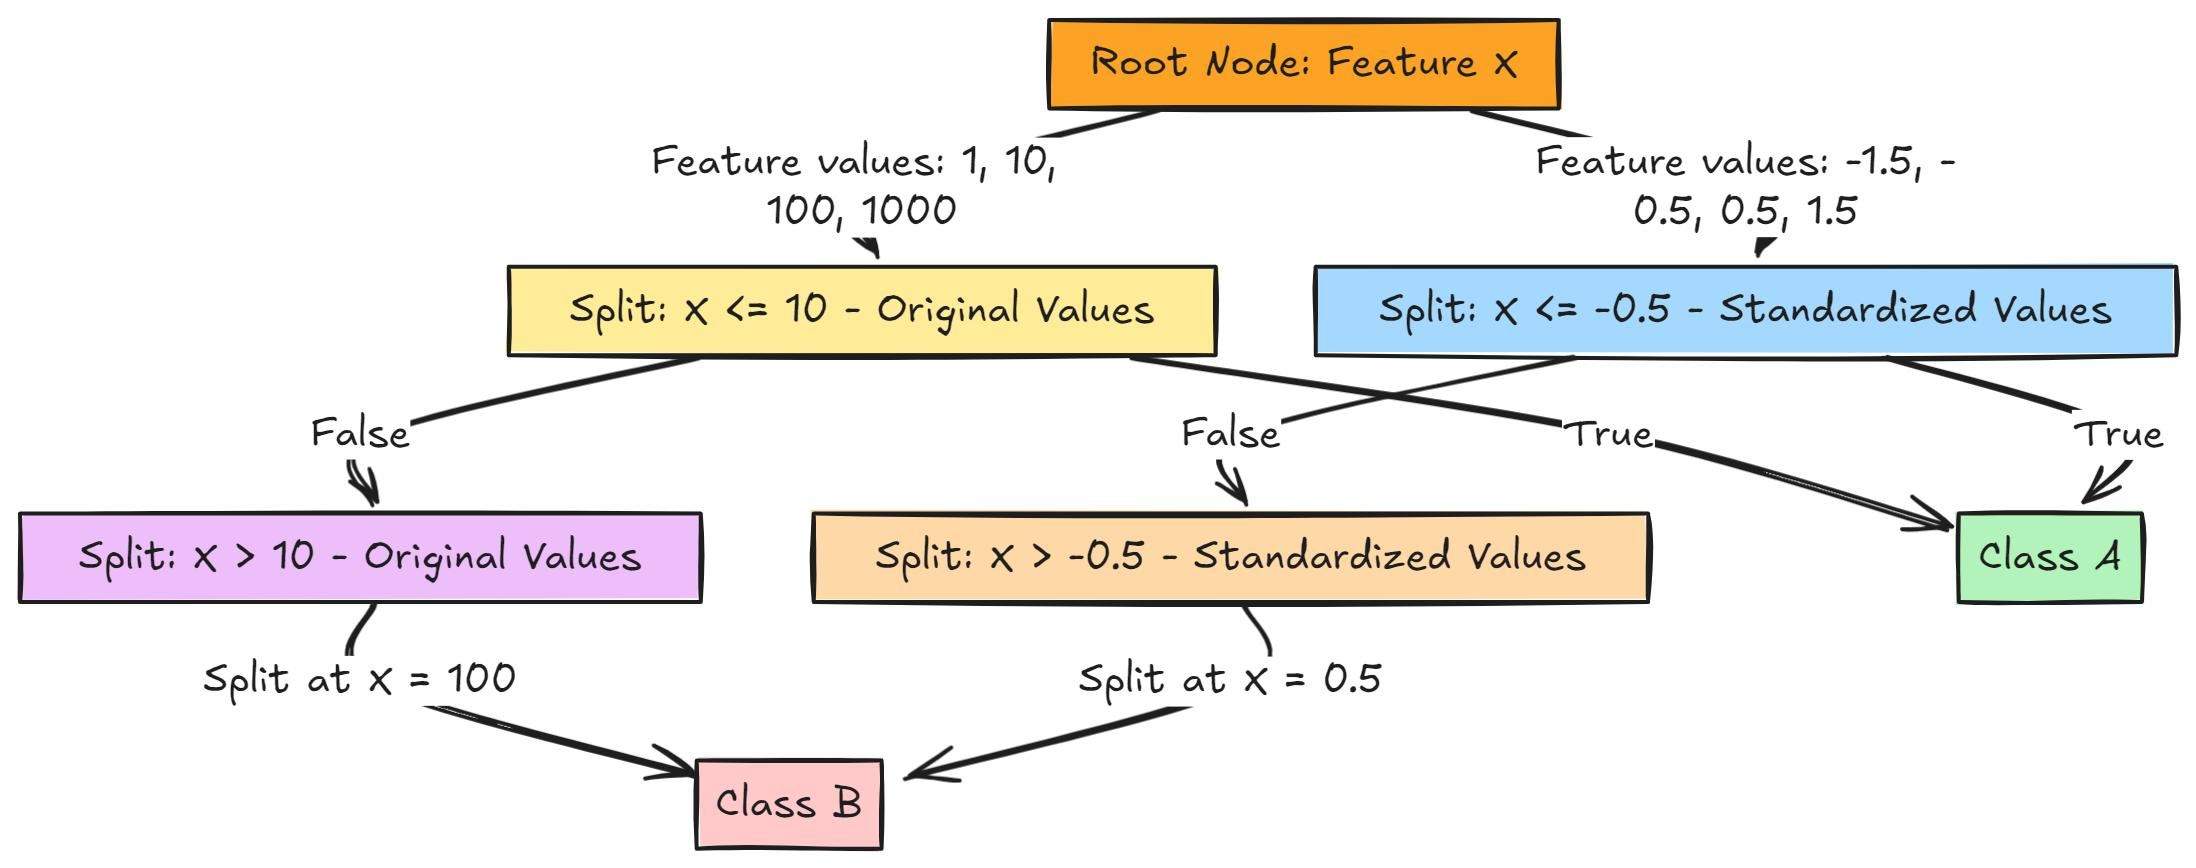
---

## 3. What is Gini Impurity?

Gini Impurity measures how mixed the classes are inside a group.

In simple words, it tells us how impure or mixed a node is.

### Formula

Gini Impurity = 1 - Σ(pᵢ)²

Where:
- pᵢ = Proportion of each class in the node.
- Σ = Sum of the squared proportions of all classes.

### Example 1: Mixed group

Suppose a group contains:

- 5 Yes
- 5 No

Total = 10

Probability of Yes = 5/10 = 0.5

Probability of No = 5/10 = 0.5

Gini = 1 - (0.5² + 0.5²)

Gini = 1 - (0.25 + 0.25)

**Gini = 0.5**

### Example 2: Pure group

Suppose a group contains:

- 10 Yes
- 0 No

Probability of Yes = 1

Probability of No = 0

Gini = 1 - (1² + 0²)

**Gini = 0**

### Interpretation

- Gini = 0 → Completely pure group.
- Higher Gini → More mixed group.
- For binary classification, the maximum Gini is 0.5.

**Goal:** A Decision Tree tries to create child nodes with lower impurity.

---

## 4. What is Entropy?

Entropy is another measure of impurity or uncertainty in a dataset.

It tells us how uncertain or mixed the classes are.

### Formula

Entropy = -Σ(pᵢ × log₂(pᵢ))

Where:
- pᵢ = Probability of a particular class.
- log₂ = Logarithm with base 2.

### Example 1: Mixed group

Suppose a group contains:

- 5 Yes
- 5 No

Probability of Yes = 0.5

Probability of No = 0.5

Entropy = -[0.5 × log₂(0.5) + 0.5 × log₂(0.5)]

Since log₂(0.5) = -1

Entropy = -[0.5 × (-1) + 0.5 × (-1)]

**Entropy = 1**

### Example 2: Pure group

Suppose a group contains:

- 10 Yes
- 0 No

Probability of Yes = 1

Probability of No = 0

Entropy = -[1 × log₂(1) + 0]

Since log₂(1) = 0

**Entropy = 0**

Note: We treat the term 0 × log₂(0) as 0 mathematically.

### Interpretation

- Entropy = 0 → Completely pure group.
- Higher Entropy → More uncertainty or mixed classes.
- For binary classification, maximum Entropy = 1.

**Goal:** Reduce entropy after splitting the dataset.

---

## 5. Difference Between Gini Impurity and Entropy

| Gini Impurity | Entropy |
|---|---|
| Measures impurity | Measures uncertainty |
| Formula: 1 - Σpᵢ² | Formula: -Σpᵢlog₂(pᵢ) |
| Pure node = 0 | Pure node = 0 |
| Binary maximum = 0.5 | Binary maximum = 1 |
| Computationally simpler | Involves logarithms |
| Used in CART | Used in ID3 and can be used in CART |

Both are used to determine the quality of a split.

### What is Information Gain?

Information Gain measures how much entropy decreases after a split.

Information Gain = Parent Entropy - Weighted Child Entropy

A higher Information Gain means a better split.

---

## 6. Why Does Feature Scaling NOT Affect Decision Trees?

This is an important concept.

Feature scaling is generally unnecessary for Decision Trees because they make decisions using **threshold-based conditions and the ordering of values**, rather than calculating distances between data points.

For example, a Decision Tree may create a condition:

Age <= 30

It divides the dataset into:

- Left branch: Age <= 30
- Right branch: Age > 30

Now suppose we apply StandardScaler.

Standardization formula:

z = (x - mean) / standard deviation

The values of Age change, and the threshold also changes.

For example:

Original Age:

20, 25, 30, 40, 50

Scaled Age (illustrative):

-1.2, -0.8, -0.4, 0.5, 1.3

The original condition:

Age <= 30

Becomes approximately:

Scaled Age <= -0.4

**Notice that the same data points are still separated into the same groups.**

The numerical values change, but their relative ordering remains the same.

Therefore, the Decision Tree can make essentially the same splits and predictions.

### Why does Logistic Regression need scaling but Decision Tree doesn't?

- Logistic Regression uses mathematical optimization and is sensitive to feature scales, especially with regularization.
- Decision Trees use threshold-based splits, so changing the scale does not generally change the ordering of values.

### Algorithms That Generally Need Scaling

- Logistic Regression
- KNN
- K-Means
- SVM
- PCA

### Algorithms That Generally Do NOT Need Scaling

- Decision Tree
- Random Forest
- XGBoost
- Gradient Boosted Trees (generally)

---


In [41]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt = DecisionTreeClassifier(random_state=0)
dt_scaled = DecisionTreeClassifier(random_state=0)

dt.fit(X_train, Y_train)
dt_scaled.fit(X_train_scaled, Y_train)

print("Original:", accuracy_score(Y_test, dt.predict(X_test)))

print("Scaled:", accuracy_score(Y_test, dt_scaled.predict(X_test_scaled)))

Original: 0.875
Scaled: 0.875


In our experiment:

Without Scaling = 0.875

With Scaling = 0.875

Both produced the same accuracy.

This happens because scaling preserves the ordering of feature values, so the Decision Tree can make equivalent splits.

---

## 8. Important Points to Remember

1. Decision Trees are supervised learning algorithms.
2. They can be used for both classification and regression.
3. They split data using features and thresholds.
4. Gini Impurity and Entropy measure impurity.
5. Gini = 0 and Entropy = 0 indicate completely pure nodes.
6. Information Gain measures the reduction in entropy.
7. Feature scaling is generally unnecessary for Decision Trees.
8. Decision Trees can overfit if they grow too deep.
9. Parameters like `max_depth`, `min_samples_split`, and `min_samples_leaf` help control overfitting.

**Final intuition:** A Decision Tree is like a series of questions. It tries to ask the questions that separate different classes as clearly as possible.

# effect of outlier

**the outliers needs to be dealt with even after scaling*

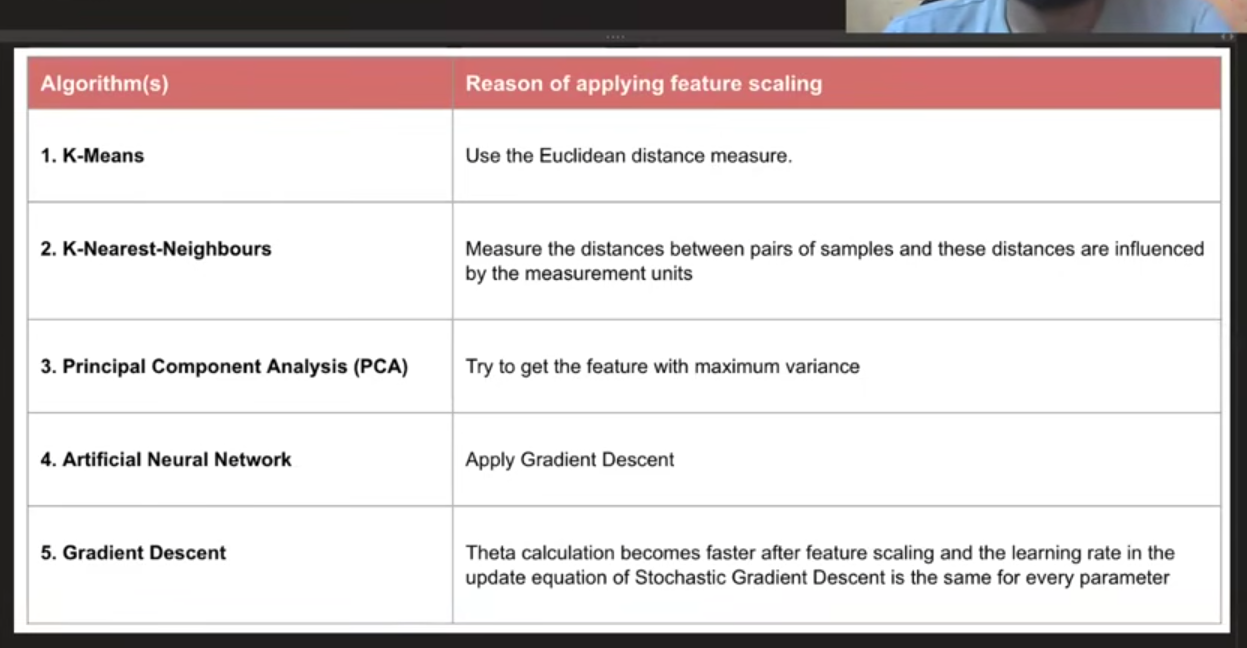